In [67]:
#DMV-3 : Customer Churn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

In [68]:
# Step 1: Load dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

In [69]:
# Step 2: Explore dataset
print("First 5 Rows:")
print(df.head())

First 5 Rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies       

In [70]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 

In [71]:
# Step 3: Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

In [72]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [73]:
# Step 4: Remove duplicates
df = df.drop_duplicates().copy()
df = df.drop_duplicates(subset="customerID").copy()

In [74]:
# Step 5: Handle missing values
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [75]:
# Step 4: Remove duplicates
df = df.drop_duplicates().copy()
df = df.drop_duplicates(subset="customerID").copy()

In [76]:
# Step 5: Handle missing values
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

In [77]:
# Step 6: Standardize text columns
text_cols = df.select_dtypes(include="object").columns

for col in text_cols:
    df[col] = df[col].str.strip()

df["gender"] = df["gender"].str.capitalize()
df["Churn"] = df["Churn"].str.capitalize()

In [78]:
# Step 7: Convert data types
df["tenure"] = df["tenure"].astype(int)
df["MonthlyCharges"] = df["MonthlyCharges"].astype(float)

In [79]:
# Step 8: Handle outliers using IQR
Q1 = df["MonthlyCharges"].quantile(0.25)
Q3 = df["MonthlyCharges"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["MonthlyCharges"] = df["MonthlyCharges"].clip(
    lower=lower, upper=upper
)

In [80]:
# Step 9: Feature engineering
df["AverageMonthlySpend"] = (
    df["TotalCharges"] / df["tenure"].replace(0, np.nan)
)

df["AverageMonthlySpend"] = df["AverageMonthlySpend"].fillna(0)

In [81]:
# Step 10: Encode target column
df["Churn_Numeric"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

In [82]:
# Step 11: Save cleaned dataset
df.to_csv("Cleaned_Telecom_Data.csv", index=False)

print("Cleaned Dataset:")
display(df.head())

Cleaned Dataset:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,AverageMonthlySpend,Churn_Numeric
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,29.850000,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,55.573529,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,54.075000,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,40.905556,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,75.825000,1


In [83]:
# Step 12: Prepare features and target
X = df.drop(columns=["customerID", "Churn", "Churn_Numeric"])
y = df["Churn_Numeric"]

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [84]:
# Step 13: Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

In [85]:
# Step 14: Normalize numerical columns
numeric_cols = [
    "tenure", "MonthlyCharges",
    "TotalCharges", "AverageMonthlySpend"
]

scaler = MinMaxScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

X_test[numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (5634, 31)
Testing Data Shape: (1409, 31)


In [86]:
# Step 15: Analyze customer churn
print("Churn Distribution:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


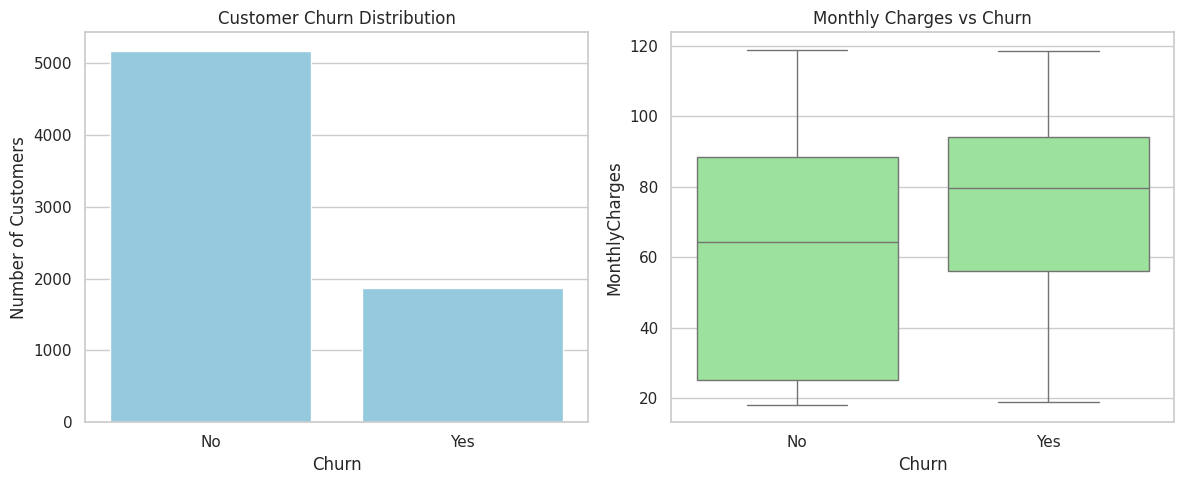


Cleaned dataset saved successfully!


In [88]:
# Step 16: Visualization
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))

# Churn distribution
plt.subplot(1, 2, 1)
sns.countplot(data=df, x="Churn", color="skyblue")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

# Monthly charges vs churn
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x="Churn", y="MonthlyCharges",color="lightgreen")
plt.title("Monthly Charges vs Churn")

plt.tight_layout()
plt.show()

print("\nCleaned dataset saved successfully!")